# 04. Longitudinal Cohort Retention & Churn Decay Analysis

### Project: E-Commerce Customer Funnel & Cohort Retention Analytics

**Objective:** Model monthly customer retention trajectories by segmenting customer bases into acquisition cohorts, tracking repeat transaction frequency over successive activity cycles, computing retention percentage decay, and constructing heatmap visualizations for lifecycle reporting.

## 1. Environment Configuration & Sanitized Data Ingestion

In [1]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv('data/retail_cleaned.csv')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print(f'Ingested {len(df):,} sanitized transactions.')

Ingested 779,425 sanitized transactions.


## 2. Acquisition Cohort Identification

Each customer is assigned to an acquisition cohort based on the calendar month of their first recorded transaction (`CohortMonth`).

In [2]:
# Extract monthly period per transaction
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

# Determine customer acquisition cohort
customer_cohorts = df.groupby('CustomerID')['InvoiceMonth'].min().reset_index()
customer_cohorts.rename(columns={'InvoiceMonth': 'CohortMonth'}, inplace=True)

# Append acquisition cohort to transactional records
df = df.merge(customer_cohorts, on='CustomerID')
df[['CustomerID', 'Invoice', 'InvoiceDate', 'InvoiceMonth', 'CohortMonth']].head()

,CustomerID,Invoice,InvoiceDate,InvoiceMonth,CohortMonth
0,13085,489434,2009-12-01 07:45:00,2009-12,2009-12
1,13085,489434,2009-12-01 07:45:00,2009-12,2009-12
2,13085,489434,2009-12-01 07:45:00,2009-12,2009-12
3,13085,489434,2009-12-01 07:45:00,2009-12,2009-12
4,13085,489434,2009-12-01 07:45:00,2009-12,2009-12


## 3. Elapsed Cycle Derivation (`CohortIndex`)

The `CohortIndex` quantifies the number of calendar months elapsed between a customer's acquisition month (`CohortMonth`) and subsequent transaction months (`InvoiceMonth`):
- `CohortIndex = 0`: In-cohort acquisition transaction.
- `CohortIndex = 1`: Return transaction 1 month post-acquisition.

In [3]:
# Calculate elapsed months between acquisition and order
df['CohortIndex'] = (
    (df['InvoiceMonth'].dt.year - df['CohortMonth'].dt.year) * 12 +
    (df['InvoiceMonth'].dt.month - df['CohortMonth'].dt.month)
)

print(f'Observed tracking horizon: 0 to {df["CohortIndex"].max()} months.')
df[['CustomerID', 'InvoiceMonth', 'CohortMonth', 'CohortIndex']].head()

Observed tracking horizon: 0 to 24 months.


,CustomerID,InvoiceMonth,CohortMonth,CohortIndex
0,13085,2009-12,2009-12,0
1,13085,2009-12,2009-12,0
2,13085,2009-12,2009-12,0
3,13085,2009-12,2009-12,0
4,13085,2009-12,2009-12,0


## 4. Active Customer Activity Matrix Construction

In [4]:
# Aggregate distinct active customers by cohort and elapsed cycle
cohort_grouped = df.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()
cohort_grouped.rename(columns={'CustomerID': 'ActiveCustomers'}, inplace=True)

# Pivot into triangular matrix
cohort_pivot = cohort_grouped.pivot_table(
    index='CohortMonth',
    columns='CohortIndex',
    values='ActiveCustomers'
)

print('Raw Active Customer Volume (First 8 Cohorts, First 6 Cycles):')
cohort_pivot.iloc[:8, :7]

Raw Active Customer Volume (First 8 Cohorts, First 6 Cycles):


CohortIndex,0,1,2,3,4,5,6
CohortMonth,,,,,,,
2009-12,955.0,337.0,319.0,406.0,363.0,343.0,360.0
2010-01,383.0,79.0,119.0,117.0,101.0,115.0,99.0
2010-02,374.0,89.0,84.0,109.0,92.0,75.0,72.0
2010-03,443.0,84.0,102.0,107.0,103.0,90.0,109.0
2010-04,294.0,57.0,57.0,48.0,54.0,66.0,81.0
2010-05,254.0,40.0,43.0,44.0,45.0,65.0,54.0
2010-06,270.0,47.0,51.0,55.0,62.0,77.0,34.0
2010-07,186.0,29.0,34.0,55.0,54.0,26.0,21.0


## 5. Retention Percentage Normalization

Active customer volumes are indexed against initial cohort acquisition volume (`CohortIndex = 0`), establishing retention rate decay curves across successive monthly intervals.

In [5]:
# Normalize by base cohort size (Column 0)
cohort_sizes = cohort_pivot[0]
retention_matrix = cohort_pivot.divide(cohort_sizes, axis=0).round(4) * 100

print('Retention Matrix in Percentage (First 8 Cohorts, First 6 Cycles):')
retention_matrix.iloc[:8, :7].round(1)

Retention Matrix in Percentage (First 8 Cohorts, First 6 Cycles):


CohortIndex,0,1,2,3,4,5,6
CohortMonth,,,,,,,
2009-12,100.0,35.3,33.4,42.5,38.0,35.9,37.7
2010-01,100.0,20.6,31.1,30.6,26.4,30.0,25.8
2010-02,100.0,23.8,22.5,29.1,24.6,20.0,19.2
2010-03,100.0,19.0,23.0,24.2,23.2,20.3,24.6
2010-04,100.0,19.4,19.4,16.3,18.4,22.4,27.6
2010-05,100.0,15.8,16.9,17.3,17.7,25.6,21.3
2010-06,100.0,17.4,18.9,20.4,23.0,28.5,12.6
2010-07,100.0,15.6,18.3,29.6,29.0,14.0,11.3


## 6. Retention Heatmap Visualization

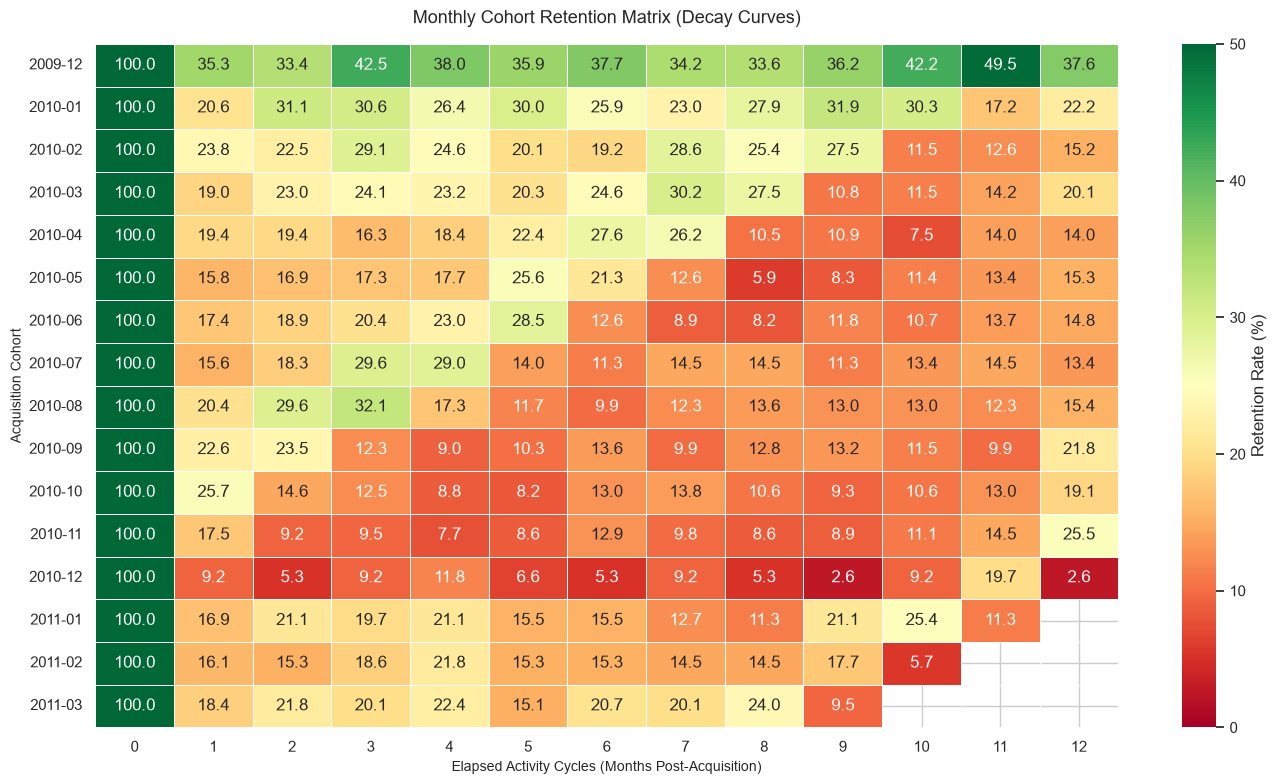

In [6]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    retention_matrix.iloc[:16, :13],
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    vmin=0,
    vmax=50,
    linewidths=0.5,
    linecolor='#ffffff',
    cbar_kws={'label': 'Retention Rate (%)'}
)

plt.title('Monthly Cohort Retention Matrix (Decay Curves)', fontsize=13, pad=15)
plt.xlabel('Elapsed Activity Cycles (Months Post-Acquisition)', fontsize=10)
plt.ylabel('Acquisition Cohort', fontsize=10)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Performance Benchmarks & Artifact Serialization

In [7]:
avg_m1 = retention_matrix[1].mean()
avg_m3 = retention_matrix[3].mean()
avg_m6 = retention_matrix[6].mean()

print('Portfolio Retention Benchmarks:')
print(f'- Month 1 Mean Retention: {avg_m1:.1f}%')
print(f'- Month 3 Mean Retention: {avg_m3:.1f}%')
print(f'- Month 6 Mean Retention: {avg_m6:.1f}%')

# Export analytical datasets
retention_matrix.to_csv('data/cohort_retention_matrix.csv')
cohort_grouped.to_csv('data/cohort_counts.csv', index=False)
print('\nSaved data/cohort_retention_matrix.csv and data/cohort_counts.csv.')

Portfolio Retention Benchmarks:
- Month 1 Mean Retention: 21.2%
- Month 3 Mean Retention: 21.6%
- Month 6 Mean Retention: 17.8%

Saved data/cohort_retention_matrix.csv and data/cohort_counts.csv.
